In [1]:
import numpy as np
from load_data import load_data

In [2]:
X_train, X_test, y_train, y_test = load_data()
print(X_train.shape)

(60000, 784)


In [10]:
first_image = X_train[0]
print(first_image.shape)

(784,)


In [24]:
# working on feed forward. Let's make a single hidden layer node

# generate 784 random weights and a random bias
rng = np.random.default_rng(seed = 42)
random_weights = rng.random(784)

# generate a random bias
random_bias = rng.random()

# construct the linear combo
next_node = np.dot(first_image, random_weights) + random_bias

# activate it
next_node = np.maximum(0, next_node)

print(next_node)

47.757276509424095


In [26]:
# now let's make a full hidden layer

hidden_layer_nodes = []

for i in range(0, 16):
    random_weights = rng.random(784)
    random_bias = rng.random()
    next_node = np.dot(first_image, random_weights) + random_bias
    next_node = np.maximum(0, next_node)
    hidden_layer_nodes.append(next_node)

print(hidden_layer_nodes)


[np.float64(55.547648592909944), np.float64(59.18504944716317), np.float64(57.93299614193306), np.float64(52.429801975804715), np.float64(54.76253959446184), np.float64(54.05214089293486), np.float64(55.401485808142), np.float64(56.839219211700026), np.float64(54.657847109429014), np.float64(50.989656739929686), np.float64(51.90757382592471), np.float64(58.81180916636981), np.float64(49.81736677785832), np.float64(53.84824516338486), np.float64(58.10240723978248), np.float64(50.56370449663893)]


In [28]:
# let's make a single output node
random_weights = rng.random(16)
random_bias = rng.random()

output_node = np.dot(hidden_layer_nodes, random_weights) + random_bias
print(output_node)

540.0219598605348


In [29]:
# now we make 10 output nodes

output_layer_nodes = []

for i in range(0, 10):
    random_weights = rng.random(16)
    random_bias = rng.random()
    output_node = np.dot(hidden_layer_nodes, random_weights) + random_bias

    output_layer_nodes.append(output_node)

print(output_layer_nodes)

[np.float64(462.0615703038839), np.float64(515.0086783695342), np.float64(415.78123878634807), np.float64(593.6207188070201), np.float64(357.1460702061876), np.float64(510.17027361669335), np.float64(490.6822355558314), np.float64(541.6596194974784), np.float64(474.5724462600708), np.float64(474.08677168172665)]


In [31]:
output_softmax = np.exp(output_layer_nodes - np.max(output_layer_nodes, axis=-1, keepdims=True))
print(output_softmax)


[7.32129255e-058 7.23143733e-035 5.82498971e-078 1.00000000e+000
 1.99693994e-103 5.72706539e-037 1.96963044e-045 2.71382161e-023
 1.98605903e-052 1.22198637e-052]


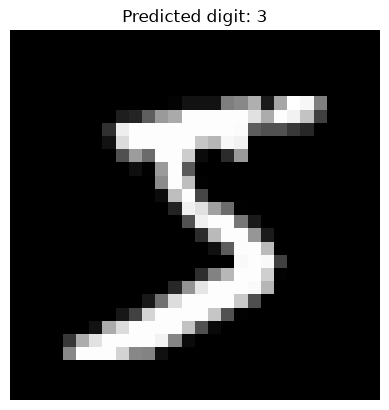

Probabilities: [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


In [32]:
import matplotlib.pyplot as plt

predicted_digit = np.argmax(output_softmax)

plt.imshow(first_image.reshape(28, 28), cmap="gray")
plt.title(f"Predicted digit: {predicted_digit}")
plt.axis("off")
plt.show()

print("Probabilities:", np.round(output_softmax, 3))